# 光谱平滑与中心定位稳定性比较
保留原模拟实验，并增加真实CSV分析。
需要的库：numpy、scipy、pandas、matplotlib。
第一部分：原模拟实验
已知真实中心时，比较三种定位方法的误差。

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter, find_peaks

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

wavelength = np.linspace(1548, 1552, 401)
true_center = 1550.25

clean_intensity = 1 - 0.6 * np.exp(
    -((wavelength - true_center) / 0.35)**2
)

原始最低点结果数量： 20
SG最低点结果数量： 20
自动寻谷结果数量： 20
原始最低点
有效测量次数： 20
平均误差：5.000 pm
MAE：25.000 pm
标准差：33.950 pm
------------------------------
SG最低点
有效测量次数： 20
平均误差：0.000 pm
MAE：19.000 pm
标准差：23.620 pm
------------------------------
SG自动寻谷
有效测量次数： 20
平均误差：0.000 pm
MAE：19.000 pm
标准差：23.620 pm
------------------------------
自动寻谷异常次数： 0


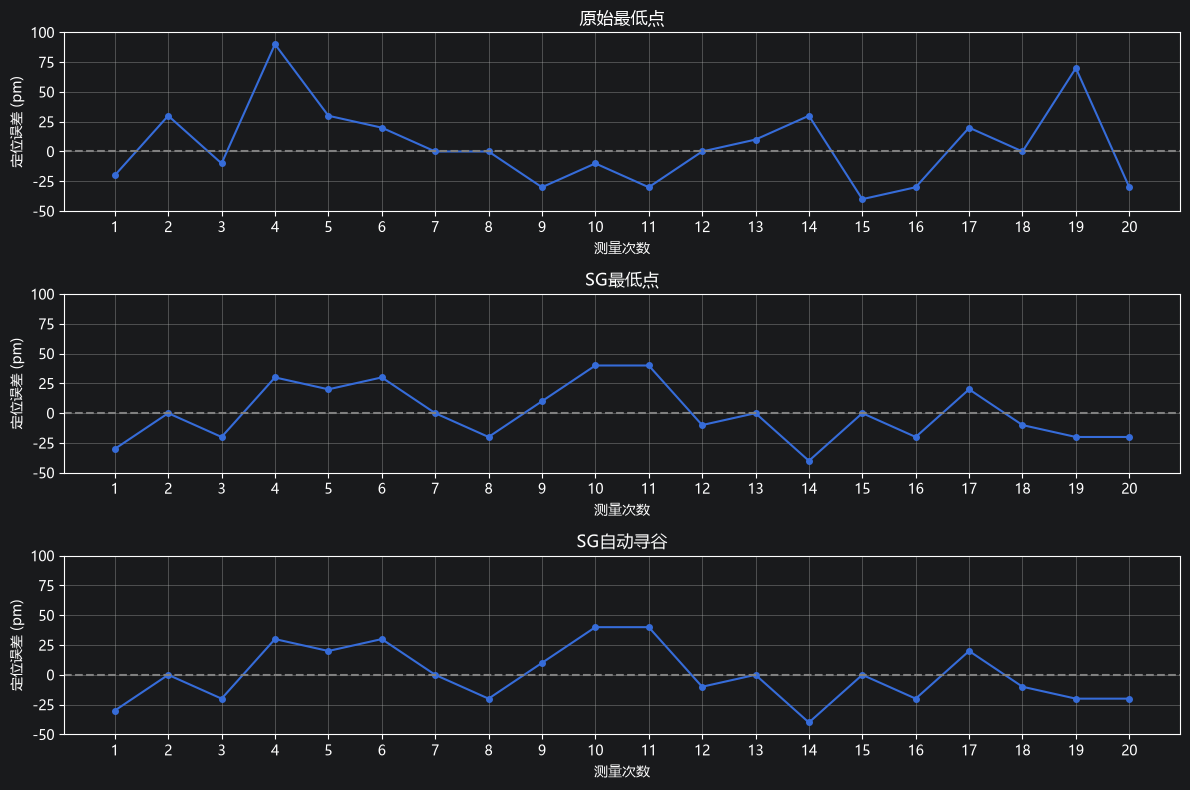

In [8]:
rng = np.random.default_rng(42)

raw_centers = []
sg_centers = []
auto_centers = []

for i in range(20):
    #添加新的噪声
    noise = rng.normal(0,0.02,size = wavelength.size)
    measured_intensity = clean_intensity + noise
    #原始光谱最低点
    raw_index = np.argmin(measured_intensity)
    raw_centers.append(wavelength[raw_index])
    #SG平滑
    smoothed_intensity = savgol_filter(measured_intensity, 11,2)
    #平滑光谱最低点
    sg_index = np.argmin(smoothed_intensity)
    sg_centers.append(wavelength[sg_index])
    #平滑后自动寻谷
    valleys,properties = find_peaks(-smoothed_intensity,prominence = 0.1,distance = 30)
    if len(valleys) ==1:
        auto_centers.append(wavelength[valleys[0]])
    else:#找不到谷，或找到多个谷，记录为行为异常
        auto_centers.append(np.nan)
        print(f'第{i + 1}次检测异常，找到{len(valleys)}个谷')
print('原始最低点结果数量：', len(raw_centers))
print('SG最低点结果数量：', len(sg_centers))
print('自动寻谷结果数量：', len(auto_centers))

raw_centers = np.array(raw_centers)
sg_centers = np.array(sg_centers)
auto_centers = np.array(auto_centers)

# 定位误差：检测中心减真实中心，换算为pm
raw_errors = (raw_centers - true_center) * 1000
sg_errors = (sg_centers - true_center) * 1000
auto_errors = (auto_centers - true_center) * 1000

# 自动寻谷只使用有效结果进行误差统计
valid_auto_errors = auto_errors[~np.isnan(auto_errors)]
error_groups = [raw_errors, sg_errors, valid_auto_errors]
method_names = ['原始最低点', 'SG最低点', 'SG自动寻谷']

for name, errors in zip(method_names, error_groups):
    print(name)
    print('有效测量次数：', len(errors))

    if len(errors) >= 2:
        print(f'平均误差：{np.mean(errors):.3f} pm')
        print(f'MAE：{np.mean(np.abs(errors)):.3f} pm')
        print(f'标准差：{np.std(errors, ddof=1):.3f} pm')
    else:
        print('有效结果不足，暂不计算完整统计量')

    print('-' * 30)

print('自动寻谷异常次数：', np.isnan(auto_centers).sum())

measurement_number = np.arange(1, 21)

plt.figure(figsize=(12, 8))

for i, errors in enumerate([raw_errors, sg_errors, auto_errors]):
    ax = plt.subplot(3, 1, i + 1)

    ax.plot(
        measurement_number,
        errors,
        'o-',
        markersize=4
    )

    ax.axhline(0, color='gray', linestyle='--')

    ax.set_title(method_names[i])
    ax.set_xlabel('测量次数')
    ax.set_ylabel('定位误差 (pm)')
    ax.set_xticks(measurement_number)
    ax.set_ylim(
        np.min(np.concatenate([raw_errors, sg_errors])) - 10,
        np.max(np.concatenate([raw_errors, sg_errors])) + 10
    )
    ax.grid(True)

plt.tight_layout()
plt.show()

本部分可独立运行。CSV第一列名为 wavelength_nm，单位必须是nm；其余每列为一次测量的光强，如 intensity_1、intensity_2。

只有一条光谱时也可以分析，但不能评价重复性。多列必须是同一实验条件下同一目标谷的重复测量。
在下面修改文件路径、光强列名、目标波长范围和检测参数。先圈定一个目标谷；不使用真实中心挑选检测结果。
示例文件 example_spectra.csv 是模拟数据，仅演示文件格式。

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter, find_peaks

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

csv_path = 'example_spectra.csv'
intensity_columns = ['intensity_1', 'intensity_2', 'intensity_3']
wave_min, wave_max = 1548, 1552  # 根据自己的目标谷修改
window_length = 11
polyorder = 2
prominence = 0.1  # 与光强尺度有关，需调整
distance = 30     # 单位是采样点间隔
reference_center = None  # 无已知参考值时保留None；有时填写nm数值


In [10]:
def analyze_spectrum(wave, intensity, window_length, polyorder, prominence, distance):
    wave = np.asarray(wave, dtype=float)
    intensity = np.asarray(intensity, dtype=float)
    if wave.ndim != 1 or intensity.shape != wave.shape or wave.size < 3:
        raise ValueError('波长与光强必须是一一对应的一维数组，至少3个点')
    if not np.all(np.isfinite(wave)) or not np.all(np.isfinite(intensity)):
        raise ValueError('请先处理缺失值或无穷值')
    steps = np.diff(wave)
    if np.any(steps <= 0):
        raise ValueError('波长必须递增且不能重复；排序时必须同步排列光强')
    if not np.allclose(steps, np.mean(steps), rtol=1e-3, atol=1e-9):
        raise ValueError('当前SG分析要求近似等间隔波长，请先重采样')
    if window_length % 2 != 1 or not 0 <= polyorder < window_length <= wave.size:
        raise ValueError('本项目使用奇数窗口，且需满足0≤阶数<窗口长度≤数据点数')
    smoothed = savgol_filter(intensity, window_length, polyorder)
    raw_center = wave[np.argmin(intensity)]
    sg_center = wave[np.argmin(smoothed)]
    valleys, properties = find_peaks(-smoothed, prominence=prominence, distance=distance)
    auto_center = wave[valleys[0]] if len(valleys) == 1 else np.nan
    return smoothed, valleys, raw_center, sg_center, auto_center


In [11]:
# 运行前请先准备CSV文件，并修改csv_path。
# CSV需包含wavelength_nm波长列（单位nm）和光强列。
# intensity_columns中的名称必须与CSV中的光强列名一致。
data = pd.read_csv(csv_path)
data = data.loc[data['wavelength_nm'].between(wave_min, wave_max)].copy()
wave = data['wavelength_nm'].to_numpy(dtype=float)

rows = []
for column in intensity_columns:
    intensity = data[column].to_numpy(dtype=float)
    smoothed, valleys, raw_center, sg_center, auto_center = analyze_spectrum(
        wave, intensity, window_length, polyorder, prominence, distance
    )
    rows.append({
        'measurement': column,
        'raw_center_nm': raw_center,
        'sg_center_nm': sg_center,
        'auto_center_nm': auto_center,
        'valley_count': len(valleys)
    })

    plt.figure(figsize=(10, 4))
    plt.plot(wave, intensity, color='gray', alpha=0.5, label='测量光谱')
    plt.plot(wave, smoothed, label='SG平滑')
    plt.scatter(wave[valleys], smoothed[valleys], color='red', zorder=3, label='检测到的谷')
    if reference_center is not None:
        plt.axvline(reference_center, color='black', linestyle='--', label='参考中心')
    plt.title(column + '：检测到' + str(len(valleys)) + '个谷')
    plt.xlabel('波长 (nm)')
    plt.ylabel('光强')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

results = pd.DataFrame(rows)
print(results)


FileNotFoundError: [Errno 2] No such file or directory: 'example_spectra.csv'

# 重复性与参考误差：
## 标准差以pm报告；没有参考中心时不计算MAE或平均定位误差。
## 单次测量的标准差留空。不同方法分别报告有效数量和异常数量，防止只看成功检测的误差。
## 真实重复性也可能受到仪器漂移、样品变化影响，不能全部归因于算法。

In [ ]:
summary_rows = []
for column in ['raw_center_nm', 'sg_center_nm', 'auto_center_nm']:
    centers = results[column].to_numpy()
    valid = centers[np.isfinite(centers)]
    record = {'method': column, 'valid_count': len(valid),
              'invalid_count': len(centers) - len(valid)}
    record['mean_center_nm'] = np.mean(valid) if len(valid) else np.nan
    record['std_pm'] = np.std(valid, ddof=1) * 1000 if len(valid) >= 2 else np.nan
    if reference_center is not None:
        errors = (valid - reference_center) * 1000
        record['mean_error_pm'] = np.mean(errors) if len(valid) else np.nan
        record['mae_pm'] = np.mean(np.abs(errors)) if len(valid) else np.nan
    summary_rows.append(record)

summary = pd.DataFrame(summary_rows)
print(summary)

# 在当前Notebook工作目录导出结果
results.to_csv('real_spectrum_centers.csv', index=False, encoding='utf-8-sig')
summary.to_csv('real_spectrum_summary.csv', index=False, encoding='utf-8-sig')
